# Background

## Reading and Working with Sequences

Analyzing the building blocks of life—DNA, RNA, and protein sequences—is the core of bioinformatics. 

DNA, RNA, and Proteins are large molecules that consist of building blocks — nucleotides (for DNA and RNA) and amino acids (for proteins).

- **DNA** = made of 4 nucleotides (A, T, C, G)
- **RNA** = made of 4 nucleotides (A, U, C, G)
- **Proteins** = made of 20 amino acids (A, R, N, D, C, E, Q, G, H, I, L, K, M, F, P, S, T, W, Y, V)

We can consider them to be strings made of characters from their respective alphabets.

### FASTA File Format
To ensure every computational tool can read and process this kind of data, researchers rely on the **FASTA file format**, a basic text-based structure used to efficiently store and represent all types of biological sequences.

The format is characterized by two lines per entry:
1. A **header line** beginning with the character "`>`", followed by a description of the sequence (usually containing gene and species names)
2. The **sequence data**

## Proteins
### Amino acids
Proteins are biopolymers composed of 20 different amino acids, which serve as their basic building blocks. Each amino acid has distinct biochemical properties that determine how a protein folds and functions. In the figure below, amino acids are grouped according to their hydrophobic or hydrophilic character, but there are other ways to classify them. 

<div style="max-width:1000px;margin-right: auto; margin-right: 0;">
    
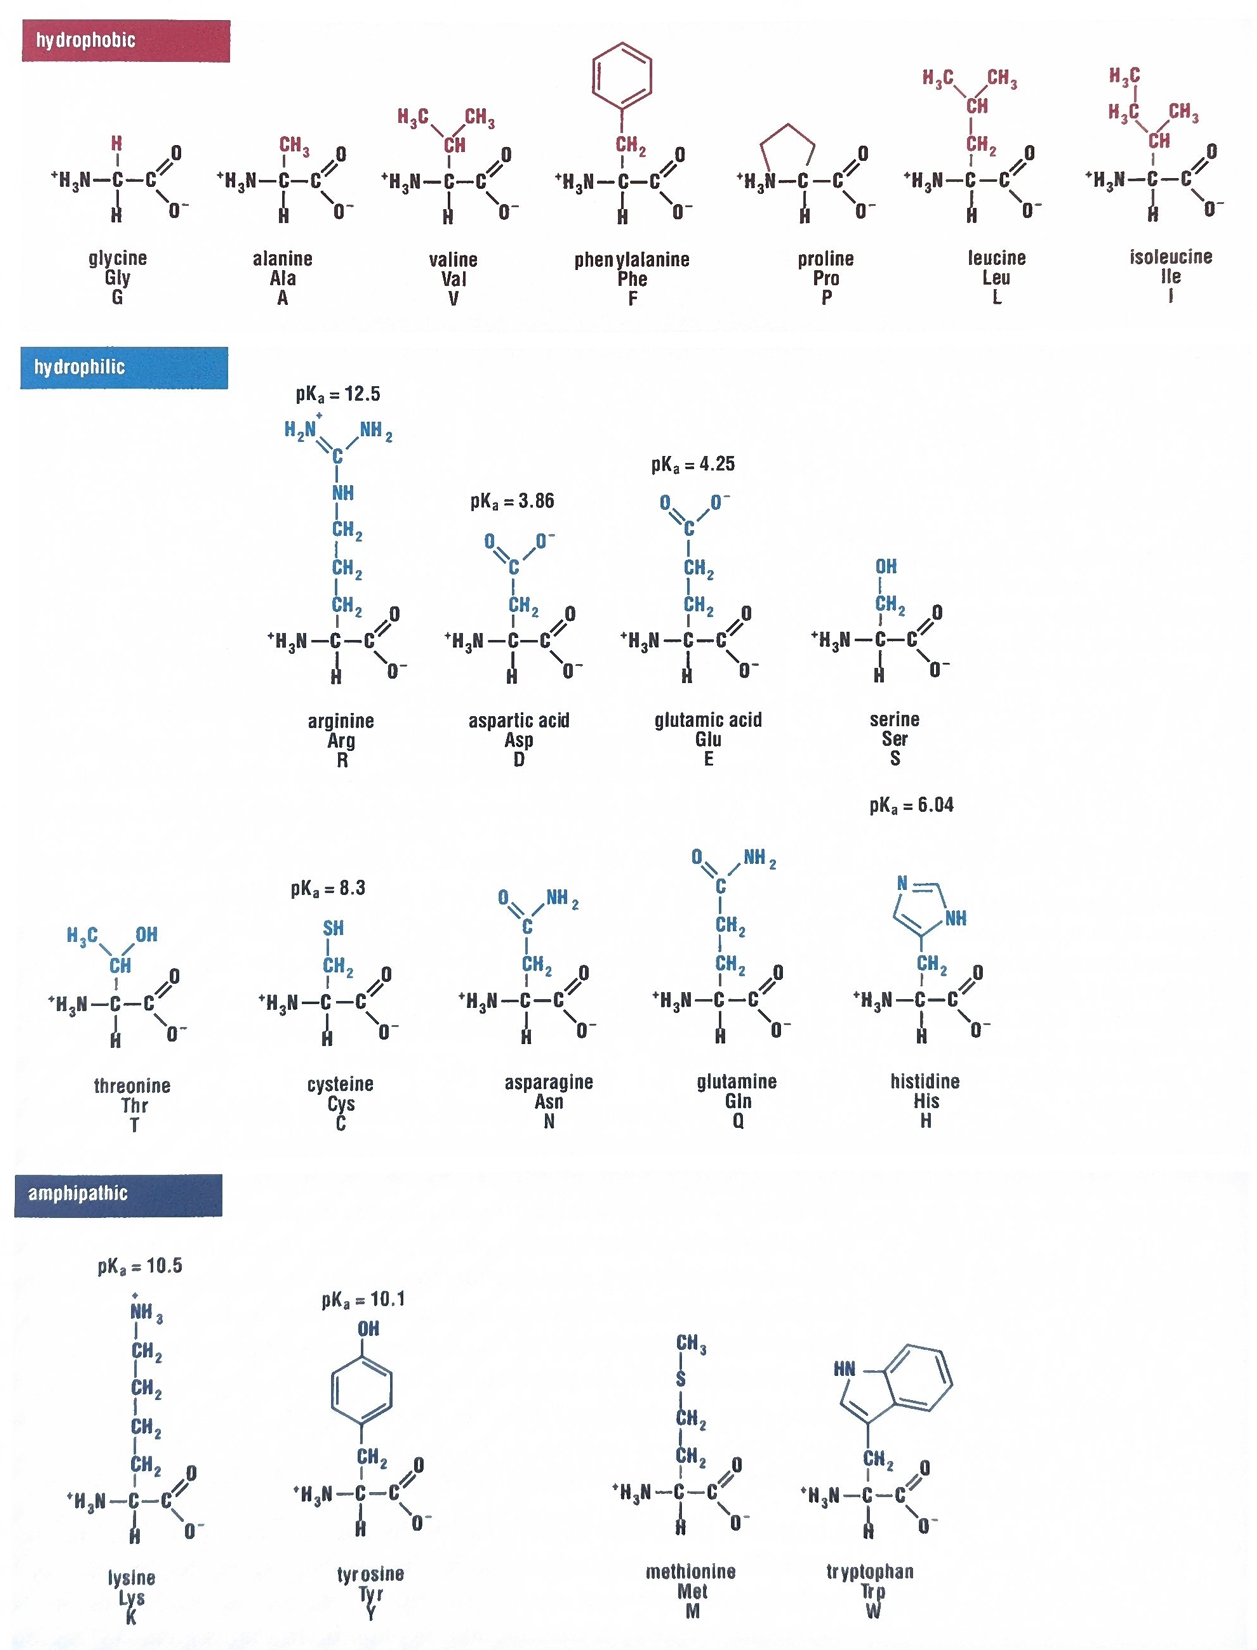
    
</div>

source: Craig, N. L., Cohen-Fix, O., Green, R., Greider, C. W., Storz, G., & Wolberger, C. *Molecular Biology: Principles of Genome Function*. Oxford University Press, 2010, p. 61. 

### Sequence motifs

Recurring patterns ("motifs") within amino acid sequences often play critical roles in the protein’s structure or function.

Functions of motifs can include:

* Binding to DNA (`RGG`)
* Interacting with other proteins (`PXXP`)
* Protein modifications (`SGRGK`)
* and many others

Identifying motifs helps researchers understand the function of unknown proteins and predict their biological roles.


### Protein structure hierarchy
Proteins fold spontaneously into a specific **three-dimensional structure** which is critical for their biological function. It is organised in distinct hierarchical levels: 
- the **primary structure** is simply the *linear sequence of amino acids*, joined by peptide bonds. Think of it as the continuous string of text in a FASTA file. This sequence is directly determined by the genetic code (DNA). All higher-level structures are dictated by this basic sequence.
- the **secondary structures** are local, *repeating shapes* that form within the linear sequence due to hydrogen bonds between atoms. The most common shapes are the *alpha-helix* (α-helix) (a spiral) and the *beta-sheet* (β-sheet) (a pleated, flat structure).
- the **tertiary structure** is the overall *three-dimensional shape of a single, complete polypeptide chain*. This "fold" is stabilized by interactions between the amino acids, including hydrophobic interactions, ionic bonds, and disulfide bridges. This is the structure that defines the protein's function (e.g., defining the specific pocket where a drug might bind).
- (**quaternary structure** exists only if the final, functional protein is made up of multiple polypeptide chains (subunits) interacting with each other. For example, hemoglobin, which transports oxygen, consists of four separate globin chains (two α and two β) held together to form a single, functional complex.)

<div style="max-width:1500px;margin-right: auto; margin-right: 0;">
    
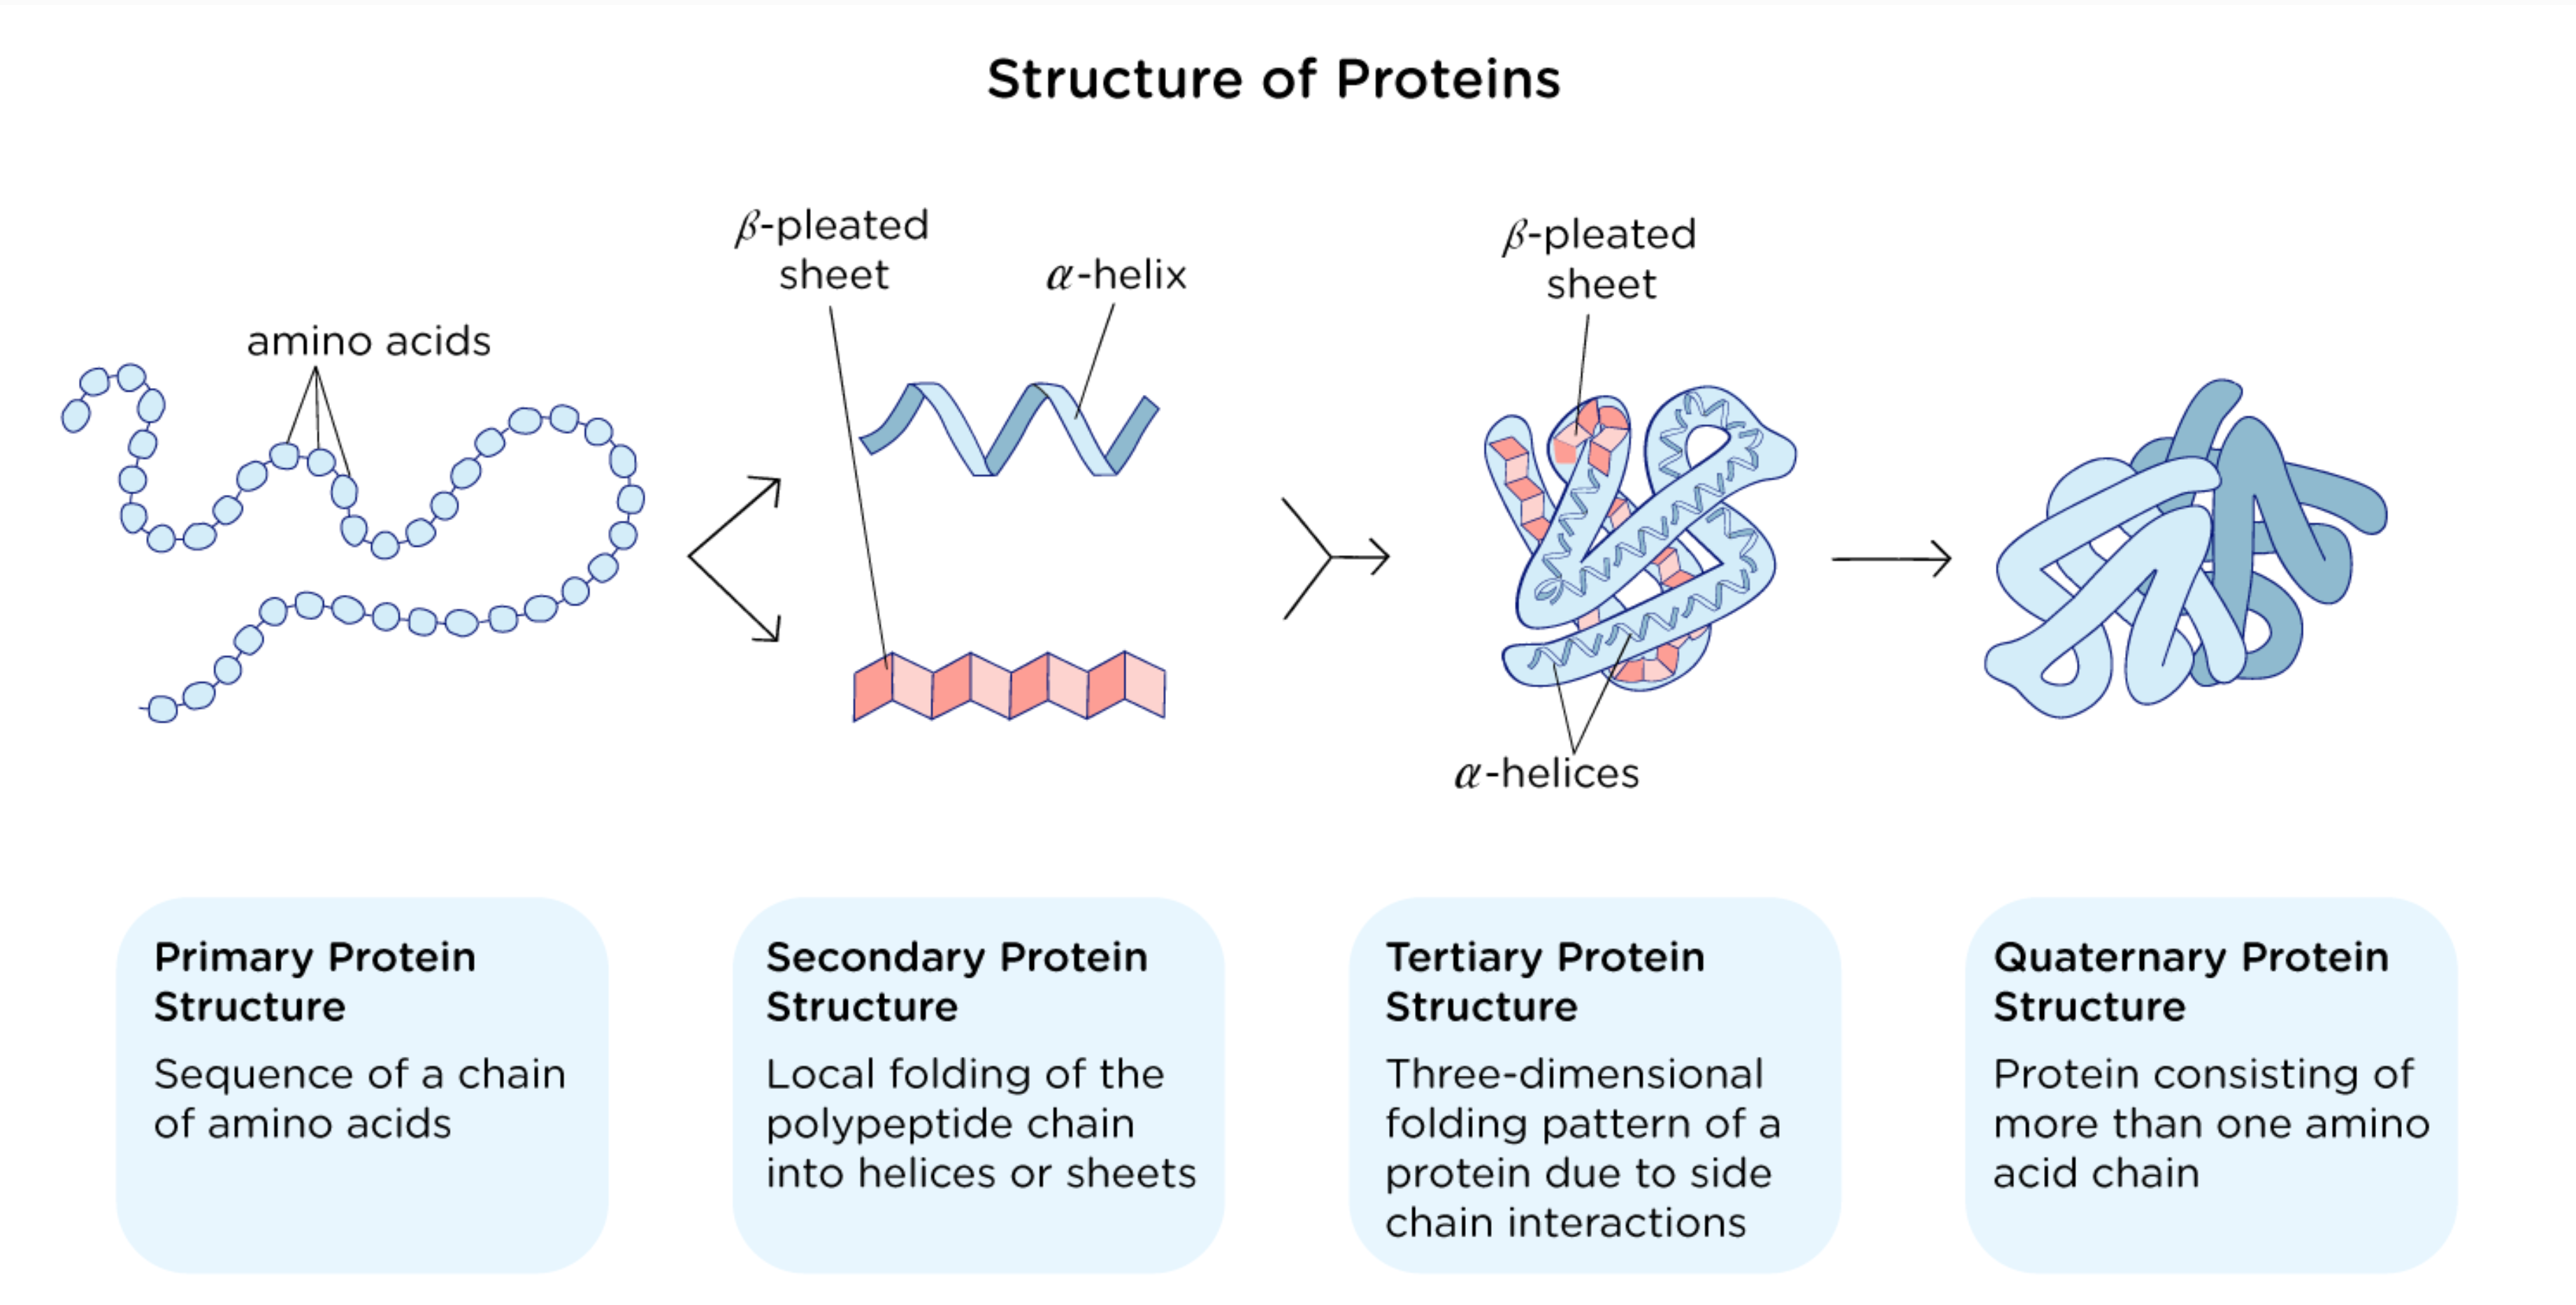
    
</div>

source: [jackwestin.com](https://jackwestin.com/mcat-books/biochemistry/peptides-and-proteins/proteins/protein-structure)

# Exercises

You can use [Biopython](https://biopython.org/docs/latest/Tutorial/index.html) (`pip install Bio`) to complete the following exercises.


#### Useful Resources:
- **PubMed**: https://pubmed.ncbi.nlm.nih.gov/ - Database for biomedical literature
- **UniProt**: https://www.uniprot.org/ - Protein sequence and functional information

## Exercise 1: Basic FASTA File Analysis

1. Load the fasta file `file1.fasta`. Which type of molecule (DNA, RNA, protein) does it describe?
2. From which species does this sequence originate? To which gene does it belong?
3. Count occurrences of the nucleotide `A` in the sequence.
4. Which nucleotide is the most abundant?
5. Subset the sequence to its first 200 nucleotides and output in a new fasta file.

In [22]:
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO
import re
from Bio.SeqUtils.ProtParam import ProteinAnalysis

record = SeqIO.read("file1.fasta", "fasta")
print(f"Description: {record.description}")
print(f"DNA , Human, Gene \"actin beta\"")

nucleotides = {n : record.count(n) for n in "ATCG"}
print(f"Number of A: {nucleotides["A"]}")

most_common = sorted(nucleotides, key=nucleotides.get, reverse=True)[0]
print(f"Most common: {most_common} with {nucleotides[most_common]}")

subset = record[:200]
SeqIO.write(subset, "file1_first200.fasta", "fasta")




Description: NG_007992.1 Homo sapiens actin beta (ACTB), RefSeqGene (LRG_132) on chromosome 7
DNA , Human, Gene "actin beta"
Number of A: 2025
Most common: C with 3070


1

## Exercise 2: Multi-entry FASTA Analysis

1. Load the fasta file `file2.fasta`. 
2. How many entries are there? What genes and which species are represented?
3. Research: What is the function of these genes? 
4. Which species has the shortest protein, and how many amino acids does it consist of?
5. Calculate the number of hydrophobic amino acids (residues) in each protein. What is the role of hydrophobic amino acids?

In [31]:
records = list(SeqIO.parse("file2.fasta", "fasta"))
print(f"Number of entries: {len(records)}, all hemoglobin")

hydrophobic = "GAVFPLI"

print()
print(f"{"Species":>25} | {"Amino Acis":>10} | {"Hydrophobic":>10}")
for record in records:
    m = re.search(r"OS=(.+?)(?= OX=)", record.description)
    species = m.group(1) if m else None
    print(f"{species:>25} | {len(record):>10} | {len([aa for aa in record.seq if (aa in hydrophobic)]):>10}")




Number of entries: 8, all hemoglobin

                  Species | Amino Acis | Hydrophobic
               Sus scrofa |        147 |         78
            Gallus gallus |        147 |         74
        Rattus norvegicus |        147 |         76
   Macaca fuscata fuscata |        147 |         76
             Homo sapiens |        147 |         79
     Arctogadus glacialis |        143 |         68
              Danio rerio |        148 |         72
              Salmo salar |        148 |         76


## Example 3: Sequence Similarity and Motif Analysis

1. Load the fasta file `file3.fasta`. 
2. What is the name of the protein described in this file? Briefly, what is its function?
3. How long are the stored sequences, and which species do they correspond to? 
4. Calculate the similarity to the human protein as the percentage of identical amino acids by position. 
5. Which species have the motif "SGRGK"?
6. Which species have the motif "SGRGK" if you allow for one mismatched position?

In [49]:
records = list(SeqIO.parse("file3.fasta", "fasta"))

# Protein: Histone H4, used for DNA packaging
human_seq = records[2].seq

def count_matches(str1, str2):
    return sum(1 if str1[i] == str2[i] else 0 for i in range(min(len(str1), len(str2))))

def contains_motif(seq, motif, max_mismatches):
    for i in range(len(seq) - len(motif) + 1):
        if count_matches(seq[i:i+len(motif)], motif) >= len(motif) - max_mismatches:
            return True
    return False

print(f"{"Species":>25} | {"Amino Acis":>10} | {"Similarity":>12}  | {"SGRGK":>10} | {"SGRGK (with mismatch)":>10}")
for record in records:
    m = re.search(r"OS=(.+?)(?= OX=)", record.description)
    species = m.group(1) if m else None
    similarity = 100 * count_matches(record, human_seq) / len(human_seq)
    has_motif = contains_motif(record, "SGRGK", 0)
    has_motif_mismatch = contains_motif(record, "SGRGK", 1)

    print(f"{species:>25} | {len(record):>10} | {similarity :>12.2f}% | {has_motif!s:>10} | {has_motif_mismatch!s:>10}")







                  Species | Amino Acis |   Similarity  |      SGRGK | SGRGK (with mismatch)
        Rattus norvegicus |        103 |       100.00% |       True |       True
             Homo sapiens |        103 |       100.00% |       True |       True
             Mus musculus |        103 |       100.00% |       True |       True
            Gallus gallus |        103 |        99.03% |       True |       True
         Penaeus vannamei |        103 |        96.12% |      False |       True
         Drosophila orena |        103 |        99.03% |      False |       True
